# 중장년(5060) 사회적 고립 위험 - 행정동 클러스터링
**참고 기법**: 김소연 외(2024) 「노인 고독사 방지를 위한 빅데이터 기반 고독사 고위험 지역 탐지 연구」
→ 요인별 단계 구분 → 축 점수 → **2차원 군집** → **HH / HL / LH / LL** 유형

| 축 | 변수 | 정의 | 위험 방향 |
|---|---|---|---|
| 인구축 | 1-1 `HH1_EXPO_5060` | 1인 세대 비율 × 5060 인구 비중 | 높을수록 |
| 인구축 | 1-2 `MALE_SHARE_5060` | 5060 인구 중 남성 비율 | 높을수록 |
| 인구축 | 1-3 `VISIBLE_IDX_50P` | (유동인구 중 5060 비중) ÷ (주민 중 5060 비중) | **낮을수록** |
| 지역축 | 2-1 `TIME_ENTROPY` | 하루 유동인구의 시간대(0\~23시) 분포 엔트로피 | **낮을수록** |
| 지역축 | 2-2 `POP_DENSITY` | 총인구 ÷ 면적(km²) | **낮을수록** |

> 1차 모델의 지역축(주간 활력·주말 활력)은 인구축과 반대로 움직여 위험이 상쇄되는 문제가 있어, 인구축과 같은 방향으로 움직이는 두 변수로 교체 (2차 모델)
> 이 노트북은 2차 모델을 정리한 **최종본**: 튜닝으로 고른 최종 모델 하나를 기준으로 위험도 5단계·판단 규칙·SHAP 설명을 모두 맞췄다

**분석 흐름**: 0. 설정 → 1. 변수 생성 → 2. 변수 점검 → 3. 단계 점수화 → 4. 기본 모델 (2D 단계점수 K-means, K=4) → 5. 튜닝 → 6. 최종 모델 선택 → 7. 최종 군집 프로파일 → 8. 위험도 5단계 → 9. 검증 → 10. SHAP → 결과 요약

## 0. 환경 설정

In [1]:
# Colab이면 드라이브 마운트, 로컬(VS Code 등)이면 건너뜀
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

In [2]:
if IN_COLAB:
    !apt-get -qq install -y fonts-nanum > /dev/null
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from scipy.stats import spearmanr

if IN_COLAB:
    fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')   # 로컬은 설치된 나눔고딕 사용
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:,.3f}'.format)
SEED = 42

In [3]:
# ---- 그래프 스타일 ----
INK, INK2, MUTED, GRID, SURF, BAND = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1', '#fcfcfb', '#f0efec'
C   = {'강남구': '#2a78d6', '춘천시': '#eb6834'}                       # 지역
CL  = {'HH': '#e34948', 'HL': '#eda100', 'LH': '#4a3aa7', 'MM': '#8a8984', 'LL': '#1baf7a'}   # 군집 (고정)
LV  = ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b']           # 위험도 1~5단계 (연→진)
DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#e34948'])

plt.rcParams.update({
    'font.family': 'NanumGothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': '#c9c8c3', 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 26,
    'axes.titlecolor': INK, 'axes.labelcolor': INK2, 'axes.labelsize': 10,
    'xtick.color': INK2, 'ytick.color': INK2, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'legend.frameon': False, 'legend.fontsize': 9, 'lines.linewidth': 2, 'lines.markersize': 7,
})

def clean(ax, grid='y'):
    ax.grid(axis='x' if grid == 'y' else 'y', visible=False); ax.tick_params(length=0)

def subtitle(ax, text):
    ax.text(0, 1.015, text, transform=ax.transAxes, fontsize=9, color=INK2, va='bottom')

def label_points(ax, xs, ys, names, gap=0.05, **kw):
    """점 이름 표시 - 이미 표시한 이름과 너무 가까우면 건너뜀 (gap = 축 범위 대비 거리)"""
    xr = np.ptp(ax.get_xlim()); yr = np.ptp(ax.get_ylim())
    placed = []
    for x, y, n in zip(xs, ys, names):
        if any(abs(x - px) / xr < gap and abs(y - py) / yr < gap for px, py in placed):
            continue
        placed.append((x, y))
        ax.annotate(n, (x, y), xytext=(6, 4), textcoords='offset points', fontsize=8, color=INK2, **kw)

# 군집 이름 · 순서 · 색 (기본 모델과 최종 모델 공통)
SPLIT = {'HH': '#e87ba4', 'HL': '#f5c96b', 'LH': '#9a8fd6', 'LL': '#7fd3b0'}     # 같은 사분면의 두 번째 군집

def name_clusters(cent, mid):
    """중심점이 축 중앙(mid) 이상이면 H, 미만이면 L (첫 글자 = 인구축, 둘째 = 지역축).
    같은 사분면에 군집이 2개 이상이면 두 축 합이 큰 순서로 번호를 붙인다 (예: HH1 = 더 위험)"""
    name = pd.Series([('H' if p >= mid else 'L') + ('H' if r >= mid else 'L') for p, r in cent.values], index=cent.index)
    for q, idx in name.groupby(name).groups.items():
        if len(idx) > 1:
            rk = cent.loc[idx].sum(axis=1).rank(ascending=False, method='first').astype(int)
            name[idx] = [f'{q}{r}' for r in rk]
    return name

def group_order(names):
    return sorted(set(names), key=lambda s: (s[0] != 'H', s[1] != 'H', s))

def group_color(n):
    return CL[n] if n in CL else (CL[n[:2]] if n.endswith('1') else SPLIT[n[:2]])

In [4]:
if IN_COLAB:
    DB = Path('/content/drive/MyDrive/빅콘/DATA/DB')
else:   # 로컬(VS Code 등): 노트북 폴더에서 위로 올라가며 저장소 루트(Knock-Model/)를 찾음
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '.gitignore').exists())
    DB = ROOT / 'database'
dt = {'SGG_CD': str, 'EMD_CD': str, 'STD_YM': str, 'BLOCK_CD': str}
read = lambda name: pd.read_csv(DB / f'{name}.csv', dtype=dt, encoding='utf-8-sig')

sgg_mst  = read('SGG_MST')
emd_mst  = read('EMD_MST')
pop      = read('POP_SEX_AGE')
hh       = read('HH_SIZE')
flow_sa  = read('FLOW_POP_SEX_AGE')
flow_tm  = read('FLOW_POP_TIME')
flow_wk  = read('FLOW_POP_WKDY')

# 유동인구에는 47개 동이 아닌 이웃 동(가평읍, 한남동 등) 행이 약 0.1% 섞여 있음 → 분석 대상 47개 동만 사용
EMD = set(emd_mst.EMD_CD)
flow_sa, flow_tm, flow_wk = [d[d.EMD_CD.isin(EMD)] for d in (flow_sa, flow_tm, flow_wk)]

SGG_NM  = dict(zip(sgg_mst.SGG_CD, sgg_mst.SGG_NM))
REGIONS = ['강남구', '춘천시']
print({n: len(d) for n, d in [('FLOW_POP_SEX_AGE', flow_sa), ('FLOW_POP_TIME', flow_tm), ('FLOW_POP_WKDY', flow_wk)]})

{'FLOW_POP_SEX_AGE': 595903, 'FLOW_POP_TIME': 570463, 'FLOW_POP_WKDY': 720153}


## 1. 파생변수 생성
- 유동인구는 각 행의 **`EMD_CD`(행정동)** 기준으로 합산해 동별 값으로 사용 (격자 정보는 사용하지 않음)
- 6개월(2025-07 \~ 12)을 합산해 월별 변동을 줄임

In [5]:
feat = emd_mst.set_index('EMD_CD')[['SGG_CD', 'EMD_NM', 'AREA_KM2', 'TOT_POP_CNT']].copy()
feat['SGG_NM'] = feat.SGG_CD.map(SGG_NM)

# ---------- 인구축 ----------
P  = pop.pivot_table(index='EMD_CD', columns=['SEX_CCD', 'AGE_CCD'], values='POP_CNT', aggfunc='sum')
PA = pop.pivot_table(index='EMD_CD', columns='AGE_CCD', values='POP_CNT', aggfunc='sum')
H  = hh.pivot_table(index='EMD_CD', columns='HH_SIZE_CCD', values='HH_CNT', aggfunc='sum')
OLD = ['60대', '70대', '80대', '90대', '100세이상']
pop5060 = PA['50대'] + PA['60대']
feat['POP_5060'] = pop5060

# 1-1 중장년 1인 세대 노출도
feat['HH1_EXPO_5060'] = (H['1인'] / H.sum(axis=1)) * (pop5060 / PA.sum(axis=1))

# 1-2 5060 남성 비율
feat['MALE_SHARE_5060'] = (P['남성']['50대'] + P['남성']['60대']) / pop5060

# 1-3 중장년 생활 노출 지수
FA = flow_sa.groupby('EMD_CD')[[c for c in flow_sa.columns if 'FLOW_POP_CNT' in c]].sum()
f50   = FA.MAN_FLOW_POP_CNT_50G + FA.WMAN_FLOW_POP_CNT_50G
f60gu = FA.MAN_FLOW_POP_CNT_60GU + FA.WMAN_FLOW_POP_CNT_60GU
r_d   = PA['60대'] / PA[OLD].sum(axis=1)                       # 주민 60세+ 중 60대 비율
flow5060 = f50 + f60gu * r_d                                   # 60GU 중 60대만 추정
resident_10p = PA.drop(columns='10대미만').sum(axis=1)          # 유동인구에 10세 미만이 없으므로 분모 맞춤
feat['VISIBLE_IDX_50P'] = (flow5060 / FA.sum(axis=1)) / (pop5060 / resident_10p)

# ---------- 지역축 ----------
# 2-1 생활 리듬 다양성: 시간대별 유동 비중 p_h → 엔트로피 -Σ p_h log p_h (최댓값 log 24 ≈ 3.178)
T = flow_tm.groupby('EMD_CD')[[f'TMST_{h:02d}' for h in range(24)]].sum()
p_h = T.div(T.sum(axis=1), axis=0)
feat['TIME_ENTROPY'] = -(p_h * np.log(p_h)).sum(axis=1)

# 2-2 물리적 밀집도: 총인구 ÷ 면적 (시군구 내 순위로 점수화하므로 log 변환 불필요)
feat['POP_DENSITY'] = feat.TOT_POP_CNT / feat.AREA_KM2

POP_AX = ['HH1_EXPO_5060', 'MALE_SHARE_5060', 'VISIBLE_IDX_50P']
REG_AX = ['TIME_ENTROPY', 'POP_DENSITY']
VARS   = POP_AX + REG_AX
RISK_UP = {'HH1_EXPO_5060': True, 'MALE_SHARE_5060': True, 'VISIBLE_IDX_50P': False,
           'TIME_ENTROPY': False, 'POP_DENSITY': False}             # True = 높을수록 위험
SHORT = {'HH1_EXPO_5060': '1-1 1인 노출', 'MALE_SHARE_5060': '1-2 남성 비율', 'VISIBLE_IDX_50P': '1-3 생활 노출',
         'TIME_ENTROPY': '2-1 생활 리듬', 'POP_DENSITY': '2-2 인구밀도'}

print('결측:', int(feat[VARS].isna().sum().sum()), '| 무한대:', int(np.isinf(feat[VARS]).sum().sum()), '| 동 수:', len(feat))
feat[['SGG_NM', 'EMD_NM'] + VARS].head()

결측: 0 | 무한대: 0 | 동 수: 47


,SGG_NM,EMD_NM,HH1_EXPO_5060,MALE_SHARE_5060,VISIBLE_IDX_50P,TIME_ENTROPY,POP_DENSITY
EMD_CD,,,,,,,
11230510,강남구,신사동,0.109,0.475,0.827,2.954,"7,979.365"
11230520,강남구,논현1동,0.166,0.485,0.962,2.965,"16,517.600"
11230530,강남구,논현2동,0.151,0.478,0.885,2.934,"13,679.592"
11230770,강남구,압구정동,0.079,0.473,0.806,2.944,"10,056.917"
11230780,강남구,청담동,0.113,0.472,0.899,2.956,"10,822.747"


## 2. 변수 점검
변수별 시군구 분포와 변수 간 상관(위험 방향 통일)은 `eda/EDA.ipynb` **8-1 · 8-2**에서 확인한다.
- 5개 변수 모두 결측·무한대 없음 (1장 출력)
- 위험 방향을 맞추면 **모든 변수 쌍의 시군구 내 순위상관이 0 이상** (−0.00 \~ +0.53) → 1차 모델처럼 서로 반대로 움직여 상쇄되는 변수가 없어 함께 군집에 쓸 수 있다

## 3. 단계 점수화 (논문의 '요인별 단계 구분 → 가중 점수')
1. 변수마다 **시군구 안에서 5분위**로 나눠 1\~5점 부여 (위험 방향으로 통일: 5점 = 가장 위험)
   - 시군구 안에서 나누는 이유: 강남·춘천은 인구밀도·상권 구조가 달라 원값을 섞으면 지역 차이가 점수를 지배
2. 축 점수 = 축에 속한 변수 점수의 **평균** (동일 가중, 1\~5점)
   - 논문은 영역 우선순위로 가중치를 줬지만 수치 근거가 없어, 기본은 동일 가중 + 9장에서 가중치 민감도 확인

In [6]:
def quintile_score(s, risk_up=True):
    """시군구 내 5분위 점수 (1~5). 위험 방향이 아닌 변수는 뒤집는다."""
    r = s.rank(method='first')
    q = pd.qcut(r, 5, labels=False) + 1
    return q if risk_up else 6 - q

S = pd.DataFrame(index=feat.index)
for k in VARS:
    S[k] = feat.groupby('SGG_CD')[k].transform(lambda s: quintile_score(s, RISK_UP[k]))

feat['POP_SCORE'] = S[POP_AX].mean(axis=1)     # 인구축 점수 (1~5)
feat['REG_SCORE'] = S[REG_AX].mean(axis=1)     # 지역축 점수 (1~5)
S.columns = [f'{k}_Q' for k in VARS]
feat = feat.join(S)

# 동점 확인: 원값이 연속값이라 시군구 안 동점이 없음 → rank(method='first')의 순서 의존 없음
print('시군구 내 동점 개수:', {k: int(feat.groupby('SGG_CD')[k].apply(lambda s: s.duplicated().sum()).sum()) for k in VARS})
feat[['SGG_NM', 'EMD_NM'] + [f'{k}_Q' for k in VARS] + ['POP_SCORE', 'REG_SCORE']].sort_values('POP_SCORE', ascending=False).head(10)

시군구 내 동점 개수: {'HH1_EXPO_5060': 0, 'MALE_SHARE_5060': 0, 'VISIBLE_IDX_50P': 0, 'TIME_ENTROPY': 0, 'POP_DENSITY': 0}


,SGG_NM,EMD_NM,HH1_EXPO_5060_Q,MALE_SHARE_5060_Q,VISIBLE_IDX_50P_Q,TIME_ENTROPY_Q,POP_DENSITY_Q,POP_SCORE,REG_SCORE
EMD_CD,,,,,,,,,
32010370,춘천시,서면,5,5,5,5,5,5.000,5.000
32010350,춘천시,남면,5,5,5,4,5,5.000,4.500
32010360,춘천시,남산면,5,4,5,5,4,4.667,4.500
32010320,춘천시,동산면,4,5,5,5,5,4.667,5.000
32010390,춘천시,북산면,5,5,3,5,5,4.333,5.000
11230520,강남구,논현1동,5,4,3,2,3,4.000,2.500
32010530,춘천시,조운동,4,3,5,2,2,4.000,2.000
11230590,강남구,삼성2동,4,4,4,5,1,4.000,3.000
32010380,춘천시,사북면,5,3,4,4,5,4.000,4.500


## 4. 기본 모델: 2D 단계점수 + K-means
논문 방식 그대로 (인구축 점수, 지역축 점수) 2차원에서 K-means. 5장 튜닝의 비교 기준이 된다

### 4-1. 최적 K 선택 (엘보우 + 실루엣)

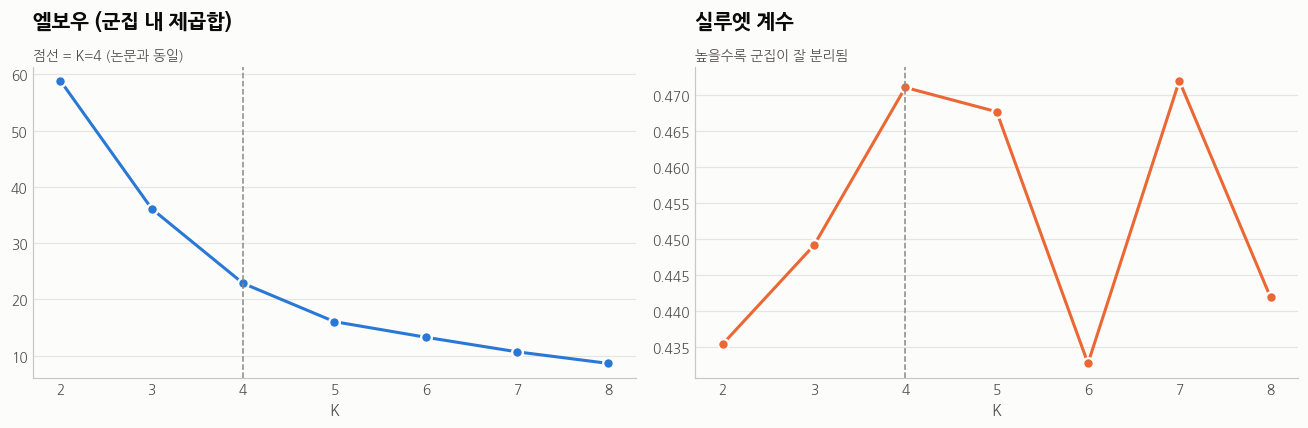

K,2,3,4,5,6,7,8
inertia,58.858,36.101,22.853,16.047,13.277,10.683,8.623
silhouette,0.435,0.449,0.471,0.468,0.433,0.472,0.442


In [7]:
X = feat[['POP_SCORE', 'REG_SCORE']].values
Ks = range(2, 9)
inertia, sil = [], []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(Ks), inertia, marker='o', color='#2a78d6', markeredgecolor=SURF, markeredgewidth=1.5)
axes[0].set_title('엘보우 (군집 내 제곱합)'); axes[0].set_xlabel('K')
axes[1].plot(list(Ks), sil, marker='o', color='#eb6834', markeredgecolor=SURF, markeredgewidth=1.5)
axes[1].set_title('실루엣 계수'); axes[1].set_xlabel('K')
for ax in axes:
    ax.axvline(4, color=MUTED, lw=1, ls='--'); clean(ax)
subtitle(axes[0], '점선 = K=4 (논문과 동일)'); subtitle(axes[1], '높을수록 군집이 잘 분리됨')
plt.tight_layout(); plt.show()
pd.DataFrame({'K': list(Ks), 'inertia': inertia, 'silhouette': sil}).set_index('K').T

**📌 해석**
- 실루엣 계수가 **K=4에서 0.471로 K=2\~6 중 가장 높음** (K=7의 0.472와 거의 같음)
- 엘보우도 K=4 이후 감소 폭이 줄어듦
- 👉 논문과 같은 **K=4** 선택. 1차 모델(0.448)보다 군집 구조가 뚜렷해짐

### 4-2. K=4 군집 → HH / HL / LH / LL

In [8]:
K = 4
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(X)
feat['CLUSTER'] = km.labels_
cent = pd.DataFrame(km.cluster_centers_, columns=['POP_SCORE', 'REG_SCORE'])

mid = 3.0                                        # 단계 점수(1~5) 축의 중앙
cent['NAME'] = name_clusters(cent[['POP_SCORE', 'REG_SCORE']], mid)
feat['GROUP'] = feat.CLUSTER.map(cent.NAME)
GROUPS = group_order(cent.NAME)
print(cent.round(2).to_string())
pd.crosstab(feat.GROUP, feat.SGG_NM, margins=True, margins_name='합계').reindex(GROUPS + ['합계'])

   POP_SCORE  REG_SCORE NAME
0      1.860      3.170   LH
1      3.960      4.370   HH
2      2.200      1.450   LL
3      3.730      2.300   HL


SGG_NM,강남구,춘천시,합계
GROUP,,,
HH,7,8,15
HL,5,5,10
LH,6,6,12
LL,4,6,10
합계,22,25,47


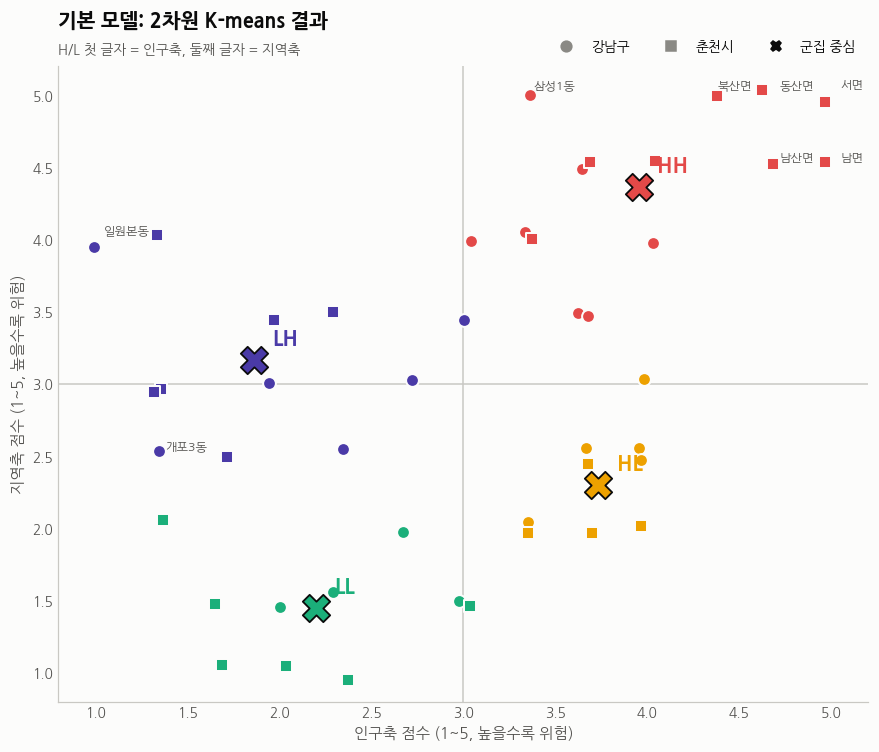

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 7.5))
ax.axhline(mid, color='#c9c8c3', lw=1); ax.axvline(mid, color='#c9c8c3', lw=1)
jit = np.random.default_rng(1).uniform(-0.06, 0.06, (len(feat), 2))     # 같은 점수 겹침 방지용 미세 흔들기
for g in GROUPS:
    for nm, mk in [('강남구', 'o'), ('춘천시', 's')]:
        d = feat[(feat.GROUP == g) & (feat.SGG_NM == nm)]
        j = jit[feat.index.get_indexer(d.index)]
        ax.scatter(d.POP_SCORE + j[:, 0], d.REG_SCORE + j[:, 1], s=70, marker=mk, color=group_color(g),
                   edgecolor=SURF, linewidth=1.3, zorder=3)
for _, r in cent.iterrows():
    ax.scatter(r.POP_SCORE, r.REG_SCORE, s=320, marker='X', color=group_color(r.NAME), edgecolor=INK, linewidth=1.2, zorder=4)
    ax.annotate(r.NAME, (r.POP_SCORE, r.REG_SCORE), xytext=(12, 10), textcoords='offset points',
                fontsize=14, fontweight='bold', color=group_color(r.NAME))
ext = pd.concat([feat.nlargest(4, 'POP_SCORE'), feat.nlargest(4, 'REG_SCORE'), feat.nsmallest(2, 'POP_SCORE')])
ext = ext[~ext.index.duplicated()]
label_points(ax, ext.POP_SCORE.tolist(), ext.REG_SCORE.tolist(), ext.EMD_NM.tolist(), gap=0.04)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=MUTED, label='강남구'),
                   Line2D([], [], marker='s', ls='', color=MUTED, label='춘천시'),
                   Line2D([], [], marker='X', ls='', color=INK, label='군집 중심')],
          loc='lower right', bbox_to_anchor=(1, 1.0), ncol=3)
ax.set_xlim(0.8, 5.2); ax.set_ylim(0.8, 5.2)
ax.set_xlabel('인구축 점수 (1~5, 높을수록 위험)'); ax.set_ylabel('지역축 점수 (1~5, 높을수록 위험)')
ax.set_title('기본 모델: 2차원 K-means 결과'); subtitle(ax, 'H/L 첫 글자 = 인구축, 둘째 글자 = 지역축')
ax.grid(False); ax.tick_params(length=0); plt.show()

**📌 해석**
| 군집 | 중심 (인구축, 지역축) | 동 수 | 소속 동 |
|---|---|---|---|
| **HH** | (4.0, 4.4) | 15 (강남 7, 춘천 8) | **춘천 외곽 면·읍 전부**(남면·서면·동산면·남산면·북산면·사북면·신동면·신북읍), 강남 역삼1동·논현2동·대치2동·수서동·신사동·삼성1동·압구정동 |
| **HL** | (3.7, 2.3) | 10 (강남 5, 춘천 5) | 강남 논현1동·삼성2동·대치4동·역삼2동·일원1동, 춘천 조운동·교동·후평1동·효자1\~2동 |
| **LH** | (1.9, 3.2) | 12 (강남 6, 춘천 6) | 강남 청담동·도곡1동·개포3\~4동·세곡동·일원본동, 춘천 근화동·동내면·소양동·동면·강남동·신사우동 |
| **LL** | (2.2, 1.5) | 10 (강남 4, 춘천 6) | 강남 대치1동·도곡2동·개포1\~2동, 춘천 석사동·효자3동·후평2\~3동·퇴계동·약사명동 |

- 네 사분면에 군집이 하나씩 나뉘어 **논문과 같은 HH / HL / LH / LL 구조**가 그대로 나옴
- 1차 모델에서 지역축 때문에 위험이 묻혔던 **춘천 외곽 면이 HH(최고위험)로 이동**

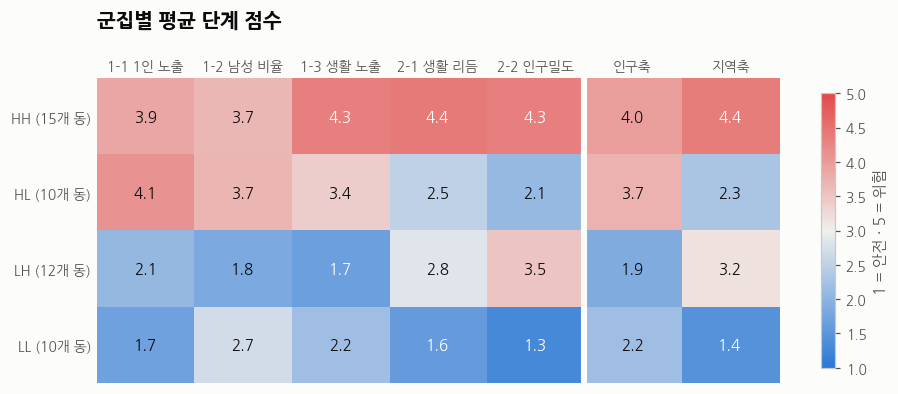

,HH1_EXPO_5060,MALE_SHARE_5060,VISIBLE_IDX_50P,TIME_ENTROPY,POP_DENSITY,TOT_POP_CNT,POP_5060
GROUP,,,,,,,
HH,0.182,0.521,0.827,2.917,"5,451.834","12,083.000","3,566.467"
HL,0.163,0.508,0.892,2.971,"14,787.793","15,221.400","4,128.700"
LH,0.105,0.481,0.996,2.960,"7,428.591","21,990.583","6,385.167"
LL,0.094,0.487,0.951,2.984,"17,493.615","24,421.800","7,260.200"


In [10]:
# 군집별 변수 평균 점수 (1~5, 5 = 가장 위험)
QCOLS = [f'{k}_Q' for k in VARS]
prof = feat.groupby('GROUP')[QCOLS + ['POP_SCORE', 'REG_SCORE']].mean().reindex(GROUPS)
prof.columns = [SHORT[k] for k in VARS] + ['인구축', '지역축']

fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(prof, cmap=DIV, vmin=1, vmax=5, aspect='auto')
ax.set_xticks(range(prof.shape[1]), prof.columns); ax.set_yticks(range(len(prof)), [f'{g} ({(feat.GROUP == g).sum()}개 동)' for g in prof.index])
for i in range(prof.shape[0]):
    for j in range(prof.shape[1]):
        ax.text(j, i, f'{prof.iloc[i, j]:.1f}', ha='center', va='center', fontsize=10,
                color='white' if abs(prof.iloc[i, j] - 3) > 1.3 else INK)
ax.axvline(4.5, color=SURF, lw=4)
ax.xaxis.tick_top(); ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title('군집별 평균 단계 점수', pad=34); fig.colorbar(im, ax=ax, shrink=0.9, label='1 = 안전 · 5 = 위험')
plt.show()

# 원값 기준 군집 평균 (해석용)
feat.groupby('GROUP')[VARS + ['TOT_POP_CNT', 'POP_5060']].mean().reindex(GROUPS)

In [11]:
# 군집별 소속 동
for g in GROUPS:
    d = feat[feat.GROUP == g].sort_values(['SGG_NM', 'POP_SCORE'], ascending=[True, False])
    print(f'■ {g} ({len(d)}개 동)')
    for nm in REGIONS:
        names = d[d.SGG_NM == nm].EMD_NM.tolist()
        if names: print(f'   {nm}: {", ".join(names)}')

■ HH (15개 동)
   강남구: 역삼1동, 논현2동, 대치2동, 수서동, 신사동, 삼성1동, 압구정동
   춘천시: 남면, 서면, 동산면, 남산면, 북산면, 사북면, 신동면, 신북읍
■ HL (10개 동)
   강남구: 논현1동, 삼성2동, 대치4동, 역삼2동, 일원1동
   춘천시: 조운동, 교동, 후평1동, 효자2동, 효자1동
■ LH (12개 동)
   강남구: 청담동, 도곡1동, 개포4동, 세곡동, 개포3동, 일원본동
   춘천시: 근화동, 동내면, 소양동, 동면, 강남동, 신사우동
■ LL (10개 동)
   강남구: 대치1동, 도곡2동, 개포1동, 개포2동
   춘천시: 석사동, 효자3동, 후평3동, 후평2동, 퇴계동, 약사명동


**📌 해석**
- **HH (15개 동)**: 다섯 변수 모두 3.7\~4.4점 → 중장년 1인 세대·남성 비율이 높고, 거리에서 덜 보이며, 하루 중 비어 있는 시간이 길고, 인구가 드묾 → **사람과 동네가 모두 취약**
- **HL (10개 동)**: 1-1 1인 노출 4.1점(최고)이지만 지역축 2.3점 → 중장년 1인 세대는 많지만 **주변에 사람이 많고 생활 리듬이 다양한 도심·대학가**
- **LH (12개 동)**: 인구축 1.9점(가장 안전)이지만 인구밀도 3.5점 → **대단지 주거지**로 지금은 저위험이나 주변 밀도는 낮은 편
- **LL (10개 동)**: 두 축 모두 낮음 → 고밀도 아파트 단지(후평·퇴계·도곡2동 등)로 상대적 저위험
- 원값 기준으로 HH의 평균 인구밀도는 약 5,450명/km²로 LL(약 17,500명/km²)의 1/3 수준

## 5. 튜닝
4장 기본 모델(2차원 단계 점수 + K-means, K=4)을 기준으로, 아래 조합을 모두 학습해 비교한다.

| 튜닝 항목 | 후보 |
|---|---|
| 입력 공간 | ① 2차원 단계 점수 (기본) ② 2차원 z-score ③ 5차원 단계 점수 ④ 5차원 z-score |
| 알고리즘 | K-means, 계층적 군집(Ward), 계층적 군집(Average), 가우시안 혼합(GMM) |
| 군집 수 K | 3, 4, 5, 6 |

**평가 지표**
- **실루엣 계수** (↑): 군집 안은 가깝고 군집 사이는 먼지
- **Davies-Bouldin 지수** (↓): 군집 간 겹침 정도
- **부트스트랩 안정성 ARI** (↑): 동을 복원추출해 다시 학습해도 같은 군집이 나오는지
- **최소 군집 크기**: 47개 동이라 너무 작은 군집(3개 동 이하)은 해석·정책 적용이 어려워 제외

> 실루엣·DB 지수는 입력 공간마다 척도가 달라 공간끼리 직접 비교하면 불공정하다 → **각 입력 공간 안에서 순위**를 매긴 뒤 종합하고, 공간 간 비교(6장)는 척도와 무관한 안정성 ARI로 한다
> 모든 K-means는 기본 모델과 같은 설정(n_init=50, SEED)이고, 안정성은 모든 모델에 같은 함수(부트스트랩 100회)를 쓴다 → 기본 모델의 지표가 4장과 5장에서 같은 값으로 나온다

In [12]:
# ---- 입력 공간 4가지 (위험 방향 통일: 값이 클수록 위험) ----
Zr = pd.DataFrame({k: feat.groupby('SGG_CD')[k].transform(lambda s: (s - s.mean()) / s.std()) * (1 if RISK_UP[k] else -1)
                   for k in VARS})
Zr_raw_dens = Zr.POP_DENSITY.copy()                                                              # 민감도 분석용 (log 미적용)
Zr['POP_DENSITY'] = feat.groupby('SGG_CD').POP_DENSITY.transform(lambda s: -(np.log(s) - np.log(s).mean()) / np.log(s).std())  # 밀도는 log 후 표준화
Qr = pd.DataFrame({k: feat[f'{k}_Q'].astype(float) for k in VARS})                               # 변수별 5분위 점수
QCOLS = [f'{k}_Q' for k in VARS]

def axis_scores(kind, pop_vars=POP_AX, reg_vars=REG_AX, src=None):
    """두 축 점수 = 축에 속한 변수의 평균 (kind: 'q' = 5분위 단계점수, 'z' = 시군구 내 z-score)"""
    src = (Qr if kind == 'q' else Zr) if src is None else src
    return src[pop_vars].mean(axis=1), src[reg_vars].mean(axis=1)

SPACES = {
    '2D 단계점수': np.c_[axis_scores('q')],
    '2D z-score':  np.c_[axis_scores('z')],
    '5D 단계점수': Qr[VARS].values,
    '5D z-score':  Zr[VARS].values,
}
assert np.allclose(SPACES['2D 단계점수'], X)                 # 4장 기본 모델 입력과 동일

# ---- 알고리즘 4가지 ----
def fit_predict(algo, Xs, k, seed=SEED):
    if algo == 'K-means':
        return KMeans(n_clusters=k, n_init=50, random_state=seed).fit_predict(Xs)
    if algo == 'Ward':
        return AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Xs)
    if algo == 'Average':
        return AgglomerativeClustering(n_clusters=k, linkage='average').fit_predict(Xs)
    if algo == 'GMM':
        return GaussianMixture(n_components=k, covariance_type='diag', n_init=5, random_state=seed).fit_predict(Xs)

def nearest_centroid(Xfit, lab, Xall):
    """부트스트랩 표본에서 만든 군집 중심으로 전체 동을 배정 (알고리즘 공통)"""
    cs = np.array([Xfit[lab == c].mean(axis=0) for c in np.unique(lab)])
    return np.argmin(((Xall[:, None, :] - cs[None]) ** 2).sum(-1), axis=1)

N_BOOT = 100
def stability(algo, Xs, k, base, n_boot=N_BOOT):
    """동을 복원추출해 다시 학습 → 전체 동 재배정 → 원래 군집과의 ARI 평균"""
    rng = np.random.default_rng(SEED); out = []
    for b in range(n_boot):
        idx = rng.choice(len(Xs), len(Xs), replace=True)
        lab = fit_predict(algo, Xs[idx], k, seed=b)
        out.append(adjusted_rand_score(base, nearest_centroid(Xs[idx], lab, Xs)))
    return np.mean(out)

In [13]:
# ---- 전체 조합 학습 (4 공간 × 4 알고리즘 × 4 K = 64개) ----
ALGOS = ['K-means', 'Ward', 'Average', 'GMM']
rows = []
for sp, Xs in SPACES.items():
    for algo in ALGOS:
        for k in [3, 4, 5, 6]:
            lab = fit_predict(algo, Xs, k)
            if len(np.unique(lab)) < k:            # 군집이 덜 만들어진 경우 제외
                continue
            rows.append({'입력공간': sp, '알고리즘': algo, 'K': k,
                         '실루엣': silhouette_score(Xs, lab),
                         'DB지수': davies_bouldin_score(Xs, lab),
                         '안정성ARI': stability(algo, Xs, k, lab),
                         '최소군집': np.bincount(lab).min(),
                         '기본모델과ARI': adjusted_rand_score(feat.CLUSTER, lab)})
tune = pd.DataFrame(rows)
print('학습한 조합:', len(tune))

# ---- 종합 순위: 입력공간 안에서 실루엣·DB·안정성 순위 평균 → 최소 군집 4개 동 이상만 ----
tune['순위_실루엣'] = tune.groupby('입력공간').실루엣.rank(ascending=False)
tune['순위_DB']     = tune.groupby('입력공간').DB지수.rank(ascending=True)
tune['순위_안정성'] = tune.groupby('입력공간').안정성ARI.rank(ascending=False)
tune['종합순위점수'] = tune[['순위_실루엣', '순위_DB', '순위_안정성']].mean(axis=1)
tune['사용가능'] = tune.최소군집 >= 4

base_idx = tune[(tune.입력공간 == '2D 단계점수') & (tune.알고리즘 == 'K-means') & (tune.K == 4)].index[0]
print('기본 모델 재현 확인 (4장 군집과 ARI):', round(tune.at[base_idx, '기본모델과ARI'], 3))

cols = ['입력공간', '알고리즘', 'K', '실루엣', 'DB지수', '안정성ARI', '최소군집', '기본모델과ARI', '종합순위점수']
(tune[tune.사용가능].sort_values(['종합순위점수', '안정성ARI'], ascending=[True, False])
     .groupby('입력공간').head(3)[cols].sort_values(['입력공간', '종합순위점수']).round(3))

학습한 조합: 64
기본 모델 재현 확인 (4장 군집과 ARI): 1.0


,입력공간,알고리즘,K,실루엣,DB지수,안정성ARI,최소군집,기본모델과ARI,종합순위점수
18,2D z-score,K-means,5,0.435,0.693,0.810,6,0.649,3.333
17,2D z-score,K-means,4,0.429,0.732,0.701,6,0.403,5.167
22,2D z-score,Ward,5,0.401,0.634,0.630,4,0.406,5.667
5,2D 단계점수,Ward,4,0.475,0.650,0.775,9,0.885,3.667
6,2D 단계점수,Ward,5,0.468,0.644,0.744,5,0.754,4.500
10,2D 단계점수,Average,5,0.468,0.644,0.710,5,0.754,5.167
50,5D z-score,K-means,5,0.242,1.222,0.590,5,0.355,3.667
51,5D z-score,K-means,6,0.231,1.238,0.559,4,0.344,5.667
55,5D z-score,Ward,6,0.216,1.184,0.554,6,0.431,6.667
35,5D 단계점수,K-means,6,0.264,1.166,0.620,5,0.508,2.333


**📌 해석** (표 = 입력 공간별 종합 상위 3개, 최소 군집 4개 동 이상만)
| 입력 공간 | 공간 내 1위 | 실루엣 | 안정성 ARI | 판단 |
|---|---|---|---|---|
| **2D 단계점수** (기본) | Ward K=4 | 0.475 | 0.775 | 분리도가 가장 좋음 |
| **2D z-score** | K-means K=5 | 0.435 | **0.810** | 안정성이 가장 좋음 |
| 5D 단계점수 | K-means K=6 | 0.264 | 0.620 | 분리도·안정성 모두 낮음 |
| 5D z-score | K-means K=5 | 0.242 | 0.590 | 분리도·안정성 모두 낮음 |

- **5개 변수를 그대로 쓰는 5차원 군집은 2차원보다 확연히 나쁨** → 논문처럼 두 축 점수로 줄여 군집하는 방식이 맞음
- 2D 단계점수에서는 기본 모델(K-means K=4: 실루엣 0.471, 안정성 0.756)과 Ward K=4(0.475, 0.775)가 거의 같은 군집 (서로 ARI 0.885) → 기본 모델이 이미 그 공간의 최적에 가까움
- 기본 모델 재현 확인 ARI 1.0 → 4장 기본 모델과 같은 설정으로 학습되어 지표가 일관됨

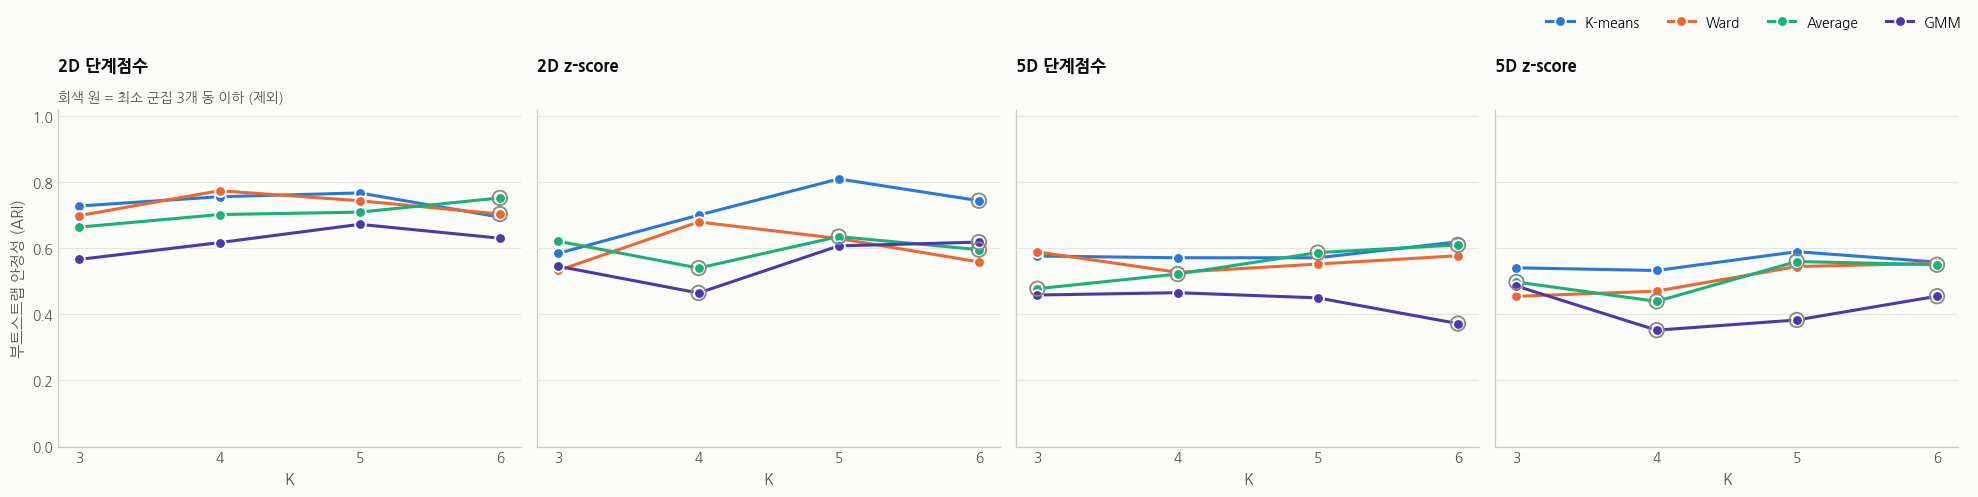

In [14]:
# 입력 공간별 · 알고리즘별 안정성 비교 (K=3~6)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
AC = {'K-means': '#2a78d6', 'Ward': '#eb6834', 'Average': '#1baf7a', 'GMM': '#4a3aa7'}
for ax, sp in zip(axes, SPACES):
    d = tune[tune.입력공간 == sp]
    for algo in ALGOS:
        e = d[d.알고리즘 == algo].sort_values('K')
        ax.plot(e.K, e.안정성ARI, marker='o', color=AC[algo], label=algo, markeredgecolor=SURF, markeredgewidth=1.2)
        small = e[~e.사용가능]
        ax.scatter(small.K, small.안정성ARI, s=90, facecolor='none', edgecolor=MUTED, linewidth=1.2, zorder=4)
    ax.set_xticks([3, 4, 5, 6]); ax.set_xlabel('K'); ax.set_ylim(0, 1.02)
    ax.set_title(sp, fontsize=11); clean(ax)
axes[0].set_ylabel('부트스트랩 안정성 (ARI)')
subtitle(axes[0], '회색 원 = 최소 군집 3개 동 이하 (제외)')
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='upper right', ncol=4, bbox_to_anchor=(1, 1.08))
plt.tight_layout(); plt.show()

**📌 해석**
- 2차원 공간(왼쪽 두 그래프)이 5차원(오른쪽 두 그래프)보다 전반적으로 안정성이 높다 (5차원은 대부분 0.6 이하)
- **2D z-score + K-means K=5의 안정성 0.81이 전체 최고**. 2D 단계점수는 알고리즘·K에 관계없이 0.6\~0.78로 고르게 안정적
- GMM(보라)은 거의 모든 조건에서 가장 불안정 → 표본 47개에 분산까지 추정하기에는 데이터가 적음
- 회색 원(최소 군집 3개 동 이하)은 Average·GMM과 K=6에서 자주 나타남 → 47개 동에서는 K=4\~5가 정책 단위로 적절

## 6. 최종 모델 선택
- 해석 가능성(사분면 HH/HL/LH/LL)을 위해 **2차원 공간**만 후보로 둔다
- ① 각 2D 공간 안에서 종합순위 1위를 뽑고, ② 두 후보는 공간과 무관하게 비교 가능한 **부트스트랩 안정성(ARI)** 으로 고른다
  - 실루엣·DB 지수는 공간끼리 척도가 달라 참고용으로만 표시

In [15]:
metrics = ['실루엣', 'DB지수', '안정성ARI', '최소군집', '기본모델과ARI']
winners = (tune[tune.사용가능 & tune.입력공간.str.startswith('2D')]
           .sort_values(['종합순위점수', '안정성ARI'], ascending=[True, False]).groupby('입력공간').head(1))
best = winners.sort_values('안정성ARI', ascending=False).iloc[0]
SPACE, ALGO, K_T = best.입력공간, best.알고리즘, int(best.K)
KIND = 'z' if 'z-score' in SPACE else 'q'
print(f'최종 모델: {SPACE} / {ALGO} / K = {K_T}')

cmp = pd.concat([tune.loc[[base_idx]].assign(구분='기본 모델 (4장)'), winners.assign(구분='공간별 1위')])
cmp.set_index(['구분', '입력공간', '알고리즘', 'K'])[metrics + ['종합순위점수']].round(3)

최종 모델: 2D z-score / K-means / K = 5


실루엣  DB지수  안정성ARI  최소군집  기본모델과ARI  종합순위점수
구분         입력공간       알고리즘    K                                            
기본 모델 (4장) 2D 단계점수    K-means 4 0.471 0.670   0.756    10     1.000   6.000
공간별 1위     2D z-score K-means 5 0.435 0.693   0.810     6     0.649   3.333
           2D 단계점수    Ward    4 0.475 0.650   0.775     9     0.885   3.667

In [16]:
# 최종 모델 학습 + 군집 이름
Xb = SPACES[SPACE]
feat['CLUSTER_T'] = fit_predict(ALGO, Xb, K_T)
feat['AX_POP'], feat['AX_REG'] = Xb[:, 0], Xb[:, 1]
mid_b = 0.0 if KIND == 'z' else 3.0              # 그래프의 축 중앙선 (z-score 중앙 = 0)

# 군집 이름은 기본 모델·논문과 같은 기준(단계 점수 1~5의 중앙 3)으로 사분면 판정 → 에이전트 파일(artifacts/)과 같은 이름
ct = feat.groupby('CLUSTER_T')[['POP_SCORE', 'REG_SCORE']].mean()
ct['NAME'] = name_clusters(ct, mid)
feat['GROUP_T'] = feat.CLUSTER_T.map(ct.NAME)
TG = group_order(ct.NAME)
CT = {g: group_color(g) for g in TG}
print(ct.round(2).to_string())
pd.crosstab(feat.GROUP_T, feat.GROUP, margins=True, margins_name='합계').reindex(TG + ['합계'])

           POP_SCORE  REG_SCORE NAME
CLUSTER_T                           
0              2.220      1.500   LL
1              4.500      4.830  HH1
2              3.530      4.000  HH2
3              3.670      2.230   HL
4              1.670      3.090   LH


GROUP,HH,HL,LH,LL,합계
GROUP_T,,,,,
HH1,6,0,0,0,6
HH2,9,0,1,0,10
HL,0,10,0,1,11
LH,0,0,10,1,11
LL,0,0,1,8,9
합계,15,10,12,10,47


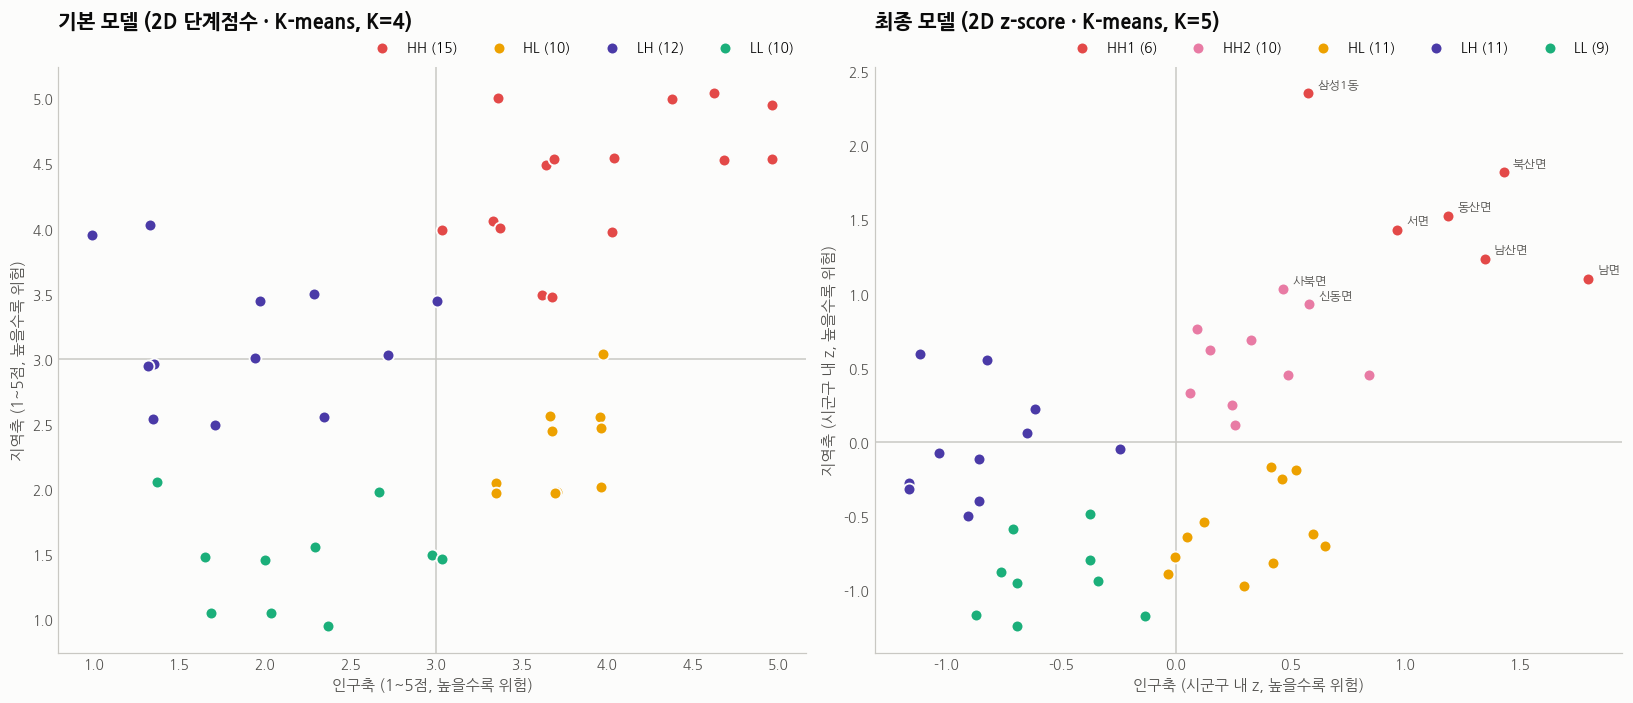

In [17]:
# 기본 모델 vs 최종 모델 (각자의 입력 공간)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
panels = [(axes[0], 'POP_SCORE', 'REG_SCORE', 'GROUP', mid, '기본 모델 (2D 단계점수 · K-means, K=4)', '1~5점'),
          (axes[1], 'AX_POP', 'AX_REG', 'GROUP_T', mid_b, f'최종 모델 ({SPACE} · {ALGO}, K={K_T})',
           '시군구 내 z' if KIND == 'z' else '1~5점')]
for ax, xc, yc, gc, m, title, unit in panels:
    ax.axhline(m, color='#c9c8c3', lw=1); ax.axvline(m, color='#c9c8c3', lw=1)
    j = np.random.default_rng(1).uniform(-0.06, 0.06, (len(feat), 2)) * (1 if unit == '1~5점' else 0)   # 동점 겹침 방지
    for g in group_order(feat[gc]):
        mask = (feat[gc] == g).values
        ax.scatter(feat.loc[mask, xc] + j[mask, 0], feat.loc[mask, yc] + j[mask, 1], s=60, color=group_color(g),
                   edgecolor=SURF, linewidth=1.2, label=f'{g} ({mask.sum()})', zorder=3)
    ax.set_xlabel(f'인구축 ({unit}, 높을수록 위험)'); ax.set_ylabel(f'지역축 ({unit}, 높을수록 위험)')
    ax.set_title(title); ax.grid(False); ax.tick_params(length=0)
    ax.legend(loc='lower right', bbox_to_anchor=(1, 1.0), ncol=len(set(feat[gc])))
top = (feat.AX_POP + feat.AX_REG).sort_values(ascending=False).index[:8]
label_points(axes[1], feat.loc[top, 'AX_POP'], feat.loc[top, 'AX_REG'], feat.loc[top, 'EMD_NM'], gap=0.03)
plt.tight_layout(); plt.show()

**📌 해석**
- 공간별 1위 후보: 2D 단계점수 → **Ward K=4** (안정성 0.775), 2D z-score → **K-means K=5** (안정성 0.810)
- 👉 공간과 무관하게 비교 가능한 안정성이 더 높은 **2D z-score + K-means, K=5를 최종 모델로 선택**
  - 실루엣은 기본 모델(0.471)·Ward(0.475)가 더 높지만 입력 공간이 달라 직접 비교 대상이 아님 (참고값)
- 기본 모델 대비 변화: **HH(15개 동)가 HH1(6)·HH2(10)으로 나뉨**. 나머지는 4개 동만 이동 (청담동 LH→HH2, 대치1동 LL→HL, 약사명동 LL→LH, 개포4동 LH→LL)
  - 연속 z-score를 쓰니 동점(같은 단계 점수)이 사라져 극단적인 동이 따로 분리됨
- **군집 이름**은 기본 모델·논문과 같은 기준(단계 점수 1\~5의 중앙 3)으로 사분면을 판정 → **HH1 / HH2 / HL / LH / LL** (같은 사분면 안에서 번호 1 = 두 축 합이 더 큰 = 더 위험한 쪽)
  - 에이전트 입력 파일(`artifacts/`)과 같은 이름
  - ⚠️ LH 군집의 지역축은 단계 점수 3.09로 중앙(3)에 가깝다 (z-score로는 −0.03, 사실상 시군구 평균) → 'LH'는 "인구축 저위험 + 지역은 평균 수준"으로 읽는다
- 오른쪽 그래프: 춘천 외곽 면 5개와 삼성1동(지역축 z 2.35)이 다른 동과 뚜렷하게 떨어진 HH1을 이룬다

## 7. 최종 모델 군집 프로파일

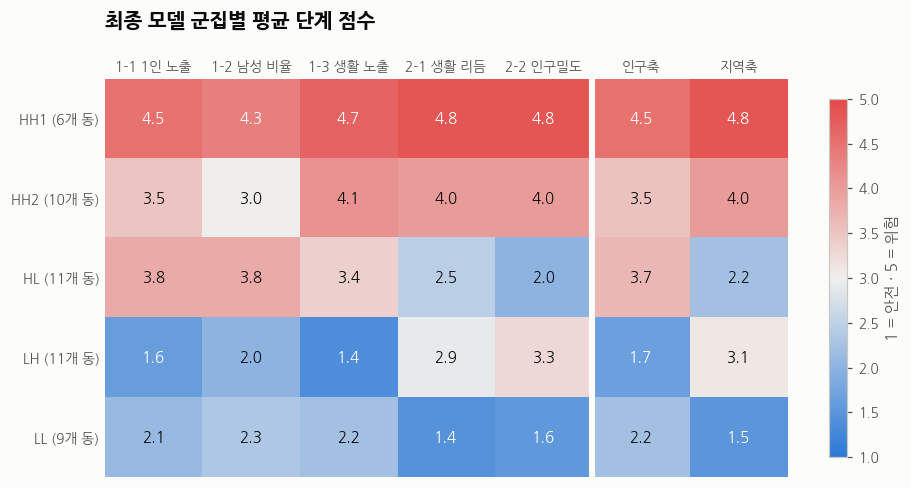

,HH1_EXPO_5060,MALE_SHARE_5060,VISIBLE_IDX_50P,TIME_ENTROPY,POP_DENSITY,TOT_POP_CNT,POP_5060
GROUP_T,,,,,,,
HH1,0.232,0.556,0.765,2.888,"1,104.451","3,792.667","1,407.167"
HH2,0.146,0.495,0.872,2.938,"8,597.355","18,370.600","5,239.900"
HL,0.150,0.510,0.901,2.970,"16,177.855","15,997.818","4,332.455"
LH,0.103,0.483,1.003,2.956,"6,635.647","20,094.909","5,784.636"
LL,0.104,0.480,0.948,2.992,"16,687.322","26,453.556","7,986.444"


In [18]:
# 군집별 변수 평균 단계 점수 (1~5, 5 = 가장 위험) - 공간과 무관하게 읽기 쉬운 5분위 점수로 표시
prof_t = feat.groupby('GROUP_T')[QCOLS + ['POP_SCORE', 'REG_SCORE']].mean().reindex(TG)
prof_t.columns = [SHORT[k] for k in VARS] + ['인구축', '지역축']
fig, ax = plt.subplots(figsize=(10, 0.7 * len(TG) + 1.2))
im = ax.imshow(prof_t, cmap=DIV, vmin=1, vmax=5, aspect='auto')
ax.set_xticks(range(prof_t.shape[1]), prof_t.columns)
ax.set_yticks(range(len(TG)), [f'{g} ({(feat.GROUP_T == g).sum()}개 동)' for g in TG])
for i in range(prof_t.shape[0]):
    for j in range(prof_t.shape[1]):
        ax.text(j, i, f'{prof_t.iloc[i, j]:.1f}', ha='center', va='center', fontsize=10,
                color='white' if abs(prof_t.iloc[i, j] - 3) > 1.3 else INK)
ax.axvline(4.5, color=SURF, lw=4); ax.xaxis.tick_top(); ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title('최종 모델 군집별 평균 단계 점수', pad=34); fig.colorbar(im, ax=ax, shrink=0.9, label='1 = 안전 · 5 = 위험')
plt.show()

# 원값 기준 군집 평균 (해석용)
feat.groupby('GROUP_T')[VARS + ['TOT_POP_CNT', 'POP_5060']].mean().reindex(TG)

In [19]:
for g in TG:
    d = feat[feat.GROUP_T == g].sort_values(['SGG_NM', 'POP_SCORE'], ascending=[True, False])
    print(f'■ {g} ({len(d)}개 동)')
    for nm in REGIONS:
        names = d[d.SGG_NM == nm].EMD_NM.tolist()
        if names: print(f'   {nm}: {", ".join(names)}')

■ HH1 (6개 동)
   강남구: 삼성1동
   춘천시: 남면, 서면, 동산면, 남산면, 북산면
■ HH2 (10개 동)
   강남구: 역삼1동, 논현2동, 대치2동, 수서동, 신사동, 압구정동, 청담동
   춘천시: 사북면, 신동면, 신북읍
■ HL (11개 동)
   강남구: 논현1동, 삼성2동, 대치4동, 역삼2동, 일원1동, 대치1동
   춘천시: 조운동, 교동, 후평1동, 효자2동, 효자1동
■ LH (11개 동)
   강남구: 도곡1동, 세곡동, 개포3동, 일원본동
   춘천시: 근화동, 동내면, 소양동, 동면, 약사명동, 강남동, 신사우동
■ LL (9개 동)
   강남구: 도곡2동, 개포1동, 개포4동, 개포2동
   춘천시: 석사동, 효자3동, 후평3동, 후평2동, 퇴계동


**📌 해석** (점수 = 5분위 단계 점수 평균, 1 = 안전 · 5 = 위험)
| 군집 | 인구축 / 지역축 | 특징 | 원값 평균 |
|---|---|---|---|
| **HH1** (6) 극고위험 | 4.5 / 4.8 | 다섯 변수 모두 4.3\~4.8점 → 사람·동네 모두 취약 | 인구밀도 1,104명/km², 총인구 3,793명, 5060 1,407명 |
| **HH2** (10) 고위험 | 3.5 / 4.0 | 생활 노출·생활 리듬·인구밀도 4점대, 남성 비율은 평균(3.0) → 지역 조건이 위험을 이끔 | 인구밀도 8,597, 5060 5,240명 |
| **HL** (11) | 3.7 / 2.2 | 1인 노출·남성 비율 3.8점이지만 인구밀도 2.0점 → 중장년 1인 세대는 많지만 붐비는 도심·대학가 | 인구밀도 16,178 |
| **LH** (11) | 1.7 / 3.1 | 1-3 생활 노출 1.4점(가장 안전) → 5060이 거리에서 활발히 보이는 주거지, 지역은 평균 수준 | 인구밀도 6,636, 5060 5,785명 |
| **LL** (9) 저위험 | 2.2 / 1.5 | 생활 리듬 1.4·인구밀도 1.6점 → 하루 종일 사람이 있는 고밀도 아파트 단지 | 인구밀도 16,687, 5060 7,986명 |

- HH1은 평균 총인구 3,793명의 **작고 인구가 드문 동**(삼성1동 제외 모두 춘천 외곽 면) → 5060 수는 적지만 위험 점수는 가장 높다
- ⚠️ 삼성1동은 강남 안에서 인구밀도가 낮고 낮 시간에만 사람이 몰리는 업무지구라 HH1에 들어감 → "업무지구에 사는 5060은 저녁·밤에 주변이 빈다"는 의미로 해석

## 8. 고립 위험도 5단계
공모전 예시('고립 위험도 5단계 지수화')에 맞춰 **종합 점수 = 인구축 단계 점수 + 지역축 단계 점수** (각 1\~5점, 동일 가중, 합 2\~10점)를 47개 동 기준 5분위로 나눈다.
- 군집(7장)은 **어떤 유형인가**(무엇을 할지), 위험도는 **얼마나 위험한가**(어디부터 할지)를 정하는 별도 결과다
- 단계 점수는 변수마다 시군구 안 5분위로 매긴 점수라 극단값의 영향을 덜 받고, 담당자에게 "1\~5점"으로 설명하기 쉽다 → 에이전트 입력 파일(`artifacts/dong_cluster.csv`)과 같은 기준
- 동점은 동 코드 순서로 나눈다
- 5단계 = 상위 20% (최우선 개입) … 1단계 = 하위 20%
- 같은 단계 안에서는 **5060 인구 수**로 우선순위를 정한다 (비율 변수는 동의 규모를 반영하지 못하기 때문)

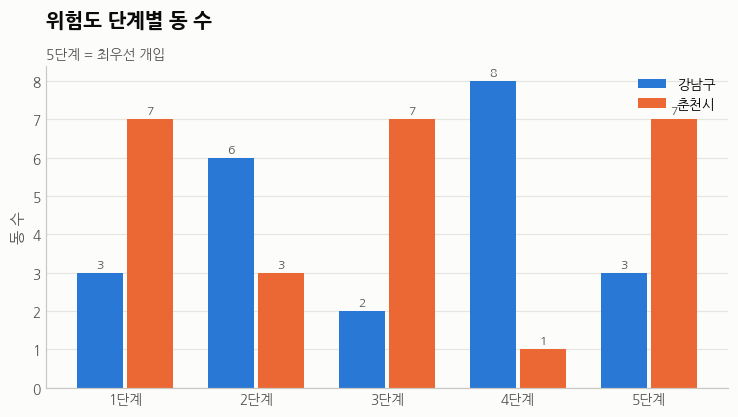

RISK_LEVEL  1  2  3  4  5
GROUP_T                  
HH1         0  0  0  0  6
HH2         0  0  0  6  4
HL          0  2  6  3  0
LH          4  4  3  0  0
LL          6  3  0  0  0 



,SGG_NM,EMD_NM,GROUP_T,RISK_LEVEL,POP_SCORE,REG_SCORE,TOTAL_SCORE,POP_5060
EMD_CD,,,,,,,,
11230640,강남구,역삼1동,HH2,5,4.000,4.000,8.000,7458
11230530,강남구,논현2동,HH2,5,3.667,4.500,8.167,5267
11230580,강남구,삼성1동,HH1,5,3.333,5.000,8.333,3894
32010370,춘천시,서면,HH1,5,5.000,5.000,10.000,1598
32010360,춘천시,남산면,HH1,5,4.667,4.500,9.167,1427
32010330,춘천시,신동면,HH2,5,3.667,4.500,8.167,1121
32010380,춘천시,사북면,HH2,5,4.000,4.500,8.500,1036
32010320,춘천시,동산면,HH1,5,4.667,5.000,9.667,576
32010390,춘천시,북산면,HH1,5,4.333,5.000,9.333,478


In [20]:
feat['TOTAL_SCORE'] = feat.POP_SCORE + feat.REG_SCORE            # 단계 점수 합 (2~10점)
feat['RISK_LEVEL'] = pd.qcut(feat.TOTAL_SCORE.rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

lv = pd.crosstab(feat.RISK_LEVEL, feat.SGG_NM)
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(5); w = 0.38
for i, nm in enumerate(REGIONS):
    bars = ax.bar(x + (i - 0.5) * w, lv[nm], width=w - 0.03, color=C[nm], label=nm)
    ax.bar_label(bars, padding=2, fontsize=8, color=INK2)
ax.set_xticks(x, [f'{l}단계' for l in range(1, 6)]); ax.set_ylabel('동 수')
ax.set_title('위험도 단계별 동 수'); subtitle(ax, '5단계 = 최우선 개입'); ax.legend(); clean(ax); plt.show()

print(pd.crosstab(feat.GROUP_T, feat.RISK_LEVEL).reindex(TG).to_string(), '\n')
(feat[feat.RISK_LEVEL >= 4]
     .sort_values(['RISK_LEVEL', 'POP_5060'], ascending=[False, False])
     [['SGG_NM', 'EMD_NM', 'GROUP_T', 'RISK_LEVEL', 'POP_SCORE', 'REG_SCORE', 'TOTAL_SCORE', 'POP_5060']])

**📌 해석**
- 군집이 위험할수록 위험도도 높다: HH1 6개 동 모두 5단계, HH2는 4\~5단계, HL 2\~4단계, LH 1\~3단계, LL 1\~2단계
  - 다만 같은 군집 안에서도 단계가 갈린다 (예: HH2 역삼1동 5단계 vs 대치2동 4단계) → 군집은 **대응 유형**, 위험도는 **우선순위**로 함께 쓴다
- **5단계 (10개 동)**: 춘천 서면·남면·동산면·북산면·남산면(HH1)·신동면·사북면(HH2), 강남 삼성1동(HH1)·역삼1동·논현2동(HH2)
- **4단계 (9개 동)**: 강남 대치2동·압구정동·청담동·수서동·신사동(HH2)·삼성2동·논현1동·대치4동(HL), 춘천 신북읍(HH2)
- 같은 단계 안 우선순위(5060 인구): 5단계에서는 역삼1동(7,458명)·논현2동(5,267명)·삼성1동(3,894명)이 규모상 우선, 춘천 면 지역은 5060이 470\~1,598명으로 적지만 점수가 가장 높다(서면 10점 만점). 4단계에서는 대치2동(10,941명)이 가장 많다
- ⚠️ 강남 5단계의 삼성1동·역삼1동은 업무지구다. 생활 리듬(낮에만 사람이 몰림)과 인구밀도(강남 최저 수준)가 위험으로 잡힌 결과라 "업무지구에 사는 5060은 저녁·밤에 주변이 빈다"는 의미로 해석해야 한다

## 9. 최종 모델 검증
정답(동별 실제 고독사) 데이터가 없으므로 세 가지로 검증한다.
1. **분리도·안정성**: 기본 모델과 같은 설정으로 잰 실루엣·DB·부트스트랩 ARI (6장 표)
2. **민감도**: 점수 방식·가중치·변수 구성을 바꿔도 순위와 군집이 유지되는가
3. **설명 가능성**: 얕은 의사결정나무가 5개 변수만으로 최종 군집을 재현하는가 → AI 에이전트의 판단 규칙

In [21]:
# 9-1 기본 모델 vs 최종 모델 (같은 함수·같은 설정)
vs = pd.DataFrame({'기본 모델 (2D 단계점수 · K-means, K=4)': tune.loc[base_idx, metrics],
                   f'최종 모델 ({SPACE} · {ALGO}, K={K_T})': best[metrics]}).astype(float)
vs.round(3)

,"기본 모델 (2D 단계점수 · K-means, K=4)","최종 모델 (2D z-score · K-means, K=5)"
실루엣,0.471,0.435
DB지수,0.670,0.693
안정성ARI,0.756,0.810
최소군집,10.000,6.000
기본모델과ARI,1.000,0.649


In [22]:
# 9-2 민감도: 최종 모델과 같은 알고리즘·K로 입력만 바꿔 다시 군집 → 최종 모델과 비교
REF_POP, REF_REG = feat.AX_POP, feat.AX_REG
REF_TOTAL = REF_POP + REF_REG                  # 최종 모델 입력의 종합 점수 (위험도 기준인 단계 점수 합과의 비교는 '척도 변경' 행)
OTHER = 'z' if KIND == 'q' else 'q'
alts = {
    f'최종 ({SPACE}, 동일 가중)':         (REF_POP, REF_REG),
    f'척도 변경 ({"2D z-score" if OTHER == "z" else "2D 단계점수"})': axis_scores(OTHER),
    '인구축 2배 가중 (논문식 우선순위)':  (REF_POP * 2, REF_REG),
    '1-2 남성 비율 제외':                axis_scores(KIND, pop_vars=['HH1_EXPO_5060', 'VISIBLE_IDX_50P']),
    '2-2 인구밀도 제외':                 axis_scores(KIND, reg_vars=['TIME_ENTROPY']),
}
if KIND == 'z':
    alts['인구밀도 log 미적용'] = axis_scores('z', src=Zr.assign(POP_DENSITY=Zr_raw_dens))

top10_base = set(REF_TOTAL.nlargest(10).index)
rows = []
for name, (a, b) in alts.items():
    total = a + b
    lab = fit_predict(ALGO, np.c_[a, b], K_T)
    rows.append({'방식': name, '종합점수 순위상관': spearmanr(total, REF_TOTAL)[0],
                 '군집 일치(ARI)': adjusted_rand_score(feat.CLUSTER_T, lab),
                 '상위 10개 동 일치': len(set(total.nlargest(10).index) & top10_base)})
pd.DataFrame(rows).set_index('방식').round(3)

,종합점수 순위상관,군집 일치(ARI),상위 10개 동 일치
방식,,,
"최종 (2D z-score, 동일 가중)",1.000,1.000,10
척도 변경 (2D 단계점수),0.973,0.792,9
인구축 2배 가중 (논문식 우선순위),0.971,0.616,9
1-2 남성 비율 제외,0.958,0.577,9
2-2 인구밀도 제외,0.922,0.425,8
인구밀도 log 미적용,0.987,0.894,9


In [23]:
# 9-3 설명 가능성: 의사결정나무(깊이 3)로 최종 군집 재현 → 5-fold 교차검증 정확도
X_rule = (Zr if KIND == 'z' else Qr)[VARS]
tree = DecisionTreeClassifier(max_depth=3, random_state=SEED)
cv = StratifiedKFold(n_splits=min(5, feat.GROUP_T.value_counts().min()), shuffle=True, random_state=SEED)
acc = cross_val_score(tree, X_rule.values, feat.GROUP_T, cv=cv)
print(f'{cv.n_splits}-fold 정확도: {acc.mean():.3f} (± {acc.std():.3f})  | fold별 {np.round(acc, 2)}')
tree.fit(X_rule.values, feat.GROUP_T)
print(f'학습 데이터 정확도: {tree.score(X_rule.values, feat.GROUP_T):.3f}')

def tree_rules(tree, names, digits=2):
    """판단 규칙 출력 - 아래 잎이 모두 같은 군집인 가지는 하나로 합친다 (불필요한 분기 제거)"""
    t, cls = tree.tree_, tree.classes_
    def leaves(n):
        if t.children_left[n] == -1:
            return {cls[t.value[n][0].argmax()]}
        return leaves(t.children_left[n]) | leaves(t.children_right[n])
    lines = []
    def rec(n, depth):
        pad = '│   ' * depth
        lc = leaves(n)
        if len(lc) == 1:
            lines.append(f'{pad}→ {lc.pop()}  ({t.n_node_samples[n]}개 동)'); return
        f, th = names[t.feature[n]], t.threshold[n]
        lines.append(f'{pad}{f} ≤ {th:.{digits}f}'); rec(t.children_left[n], depth + 1)
        lines.append(f'{pad}{f} > {th:.{digits}f}');  rec(t.children_right[n], depth + 1)
    rec(0, 0)
    return '\n'.join(lines)

unit = '시군구 내 z, 클수록 위험' if KIND == 'z' else '1~5점, 클수록 위험'
print(f'\n[판단 규칙 - AI 에이전트용] ({unit})')
print(tree_rules(tree, [SHORT[k] for k in VARS]))

5-fold 정확도: 0.633 (± 0.100)  | fold별 [0.8  0.7  0.56 0.56 0.56]
학습 데이터 정확도: 0.915

[판단 규칙 - AI 에이전트용] (시군구 내 z, 클수록 위험)
1-3 생활 노출 ≤ -0.73
│   1-2 남성 비율 ≤ 0.16
│   │   → LH  (10개 동)
│   1-2 남성 비율 > 0.16
│   │   → LL  (2개 동)
1-3 생활 노출 > -0.73
│   2-2 인구밀도 ≤ 0.02
│   │   1-2 남성 비율 ≤ -0.48
│   │   │   → LL  (6개 동)
│   │   1-2 남성 비율 > -0.48
│   │   │   → HL  (14개 동)
│   2-2 인구밀도 > 0.02
│   │   2-1 생활 리듬 ≤ 1.05
│   │   │   → HH2  (10개 동)
│   │   2-1 생활 리듬 > 1.05
│   │   │   → HH1  (5개 동)


**📌 해석**
| 검증 | 기본 모델 (K=4) | 최종 모델 (K=5) | 판단 |
|---|---|---|---|
| 실루엣 계수 | 0.471 | 0.435 | 입력 공간이 달라 참고값 |
| Davies-Bouldin (↓) | 0.670 | 0.693 | 비슷 |
| 부트스트랩 안정성 (ARI) | 0.756 | **0.810** | 최종 모델이 더 안정적 |
| 최소 군집 크기 | 10 | 6 | HH1이 6개 동 |

- 두 모델 지표는 **같은 함수·같은 설정**(K-means n_init=50, 부트스트랩 100회)으로 쟀다 → 4장·5장·9장의 기본 모델 수치가 모두 같다
- **민감도**: 점수 방식·가중치·변수 구성을 바꿔도 종합점수 순위상관 **0.92\~0.99**, 상위 10개 동 **8\~10개 일치** → 위험도 순위는 견고
  - 위험도 기준인 단계 점수 합과 최종 모델 입력(z-score) 합의 순위상관은 0.973 ('척도 변경' 행) → 어느 점수로 줄 세워도 순위가 거의 같다
  - 군집 일치(ARI)는 인구밀도 log 미적용 0.89, 5분위 단계점수 0.79, 인구축 2배 0.62, 남성 비율 제외 0.58, **인구밀도 제외 0.43** → 군집 경계는 인구밀도에 가장 민감
- **판단 규칙** (의사결정나무, 깊이 3): 5-fold 정확도 **0.63** (± 0.10), 학습 데이터 0.92
  - 1차 분기는 1-3 생활 노출: z ≤ −0.73 (5060이 거리에서 잘 보임) → LH/LL
  - 그 외에서 2-2 인구밀도 z > 0.02 (밀도 낮음) → 2-1 생활 리듬 z > 1.05면 **HH1**, 아니면 **HH2**
  - 밀도가 높으면 1-2 남성 비율 z > −0.48 → **HL**, 아니면 LL
  - 군집이 5개로 늘고 가장 작은 군집이 6개 동이라 4개 군집보다 재현이 어렵다 → 규칙은 AI 에이전트의 **1차 분류 참고용**, 최종 판단은 군집 결과와 10장 판별 근거를 함께 쓴다
  - 2차 노트북의 규칙(정확도 0.75)은 기본 모델 군집을 재현한 것이라 최종 모델과 맞지 않아 교체했다. 같은 군집으로 끝나는 불필요한 분기는 합쳐서 출력

## 10. SHAP 분석 - 군집 유형 설명
K-means는 예측 모델이 아니어서 SHAP을 직접 쓸 수 없다. 그래서 **대리 모델(surrogate)** 을 거친다.
1. 5개 파생변수로 **6장 최종 모델의 군집을 맞히는 랜덤포레스트**를 학습
2. 대리 모델의 정확도를 먼저 확인 (설명의 신뢰도)
3. SHAP으로 **전체 변수 중요도**와 **동별로 왜 그 군집인지**를 분해

- 입력: 시군구 내 z-score (위험 방향 통일, 값이 클수록 위험). 1\~5 단계 점수보다 세밀한 설명을 위해 사용
- 설명 대상은 **군집 유형**. 위험도 5단계는 두 축의 단순 합이라 SHAP으로 분해할 필요가 없음

In [24]:
import warnings
try:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')          # shap 불러올 때 진행막대(tqdm) 안내 경고만 숨김
        import shap
except ImportError:                       # Colab 등 shap이 없는 환경
    %pip install -q shap
    import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold

# 입력: 시군구 내 z-score, 위험 방향 통일 (인구밀도는 log 후 표준화) = 5장의 Zr
Xs_df = Zr[VARS].copy()
Xs_df.columns = [SHORT[k] for k in VARS]
y_grp = feat.GROUP_T.values

# 대리 모델: 표본이 47개라 과적합을 막기 위해 얕은 나무(max_depth=3)·잎 최소 3개
rf = RandomForestClassifier(n_estimators=500, max_depth=3, min_samples_leaf=3, random_state=SEED)
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=SEED)
acc_rf = cross_val_score(rf, Xs_df.values, y_grp, cv=cv_rep)
print(f'대리 모델 정확도 (반복 5-fold × 20): {acc_rf.mean():.3f} (± {acc_rf.std():.3f})')
rf.fit(Xs_df.values, y_grp)
print(f'학습 데이터 정확도: {rf.score(Xs_df.values, y_grp):.3f}')

대리 모델 정확도 (반복 5-fold × 20): 0.710 (± 0.133)


학습 데이터 정확도: 0.979


**📌 해석**
- 대리 모델(랜덤포레스트) 정확도: **반복 5-fold × 20 기준 0.710 (± 0.13)** → 5개 군집을 약 7/10 맞힘 (9-3 의사결정나무 0.63보다 높음)
- 학습 데이터 정확도 0.98 → 47개 동 전체에서는 거의 그대로 재현
- ⚠️ 표본이 47개라 정확도의 표준편차(±0.13)가 크다. SHAP 결과는 '대리 모델이 군집을 어떻게 구분했는가'에 대한 설명이며, 정확도가 100%가 아니라는 점을 함께 밝혀야 한다

SHAP 배열 크기: (47, 5, 5) | 군집 순서: ['HH1', 'HH2', 'HL', 'LH', 'LL']


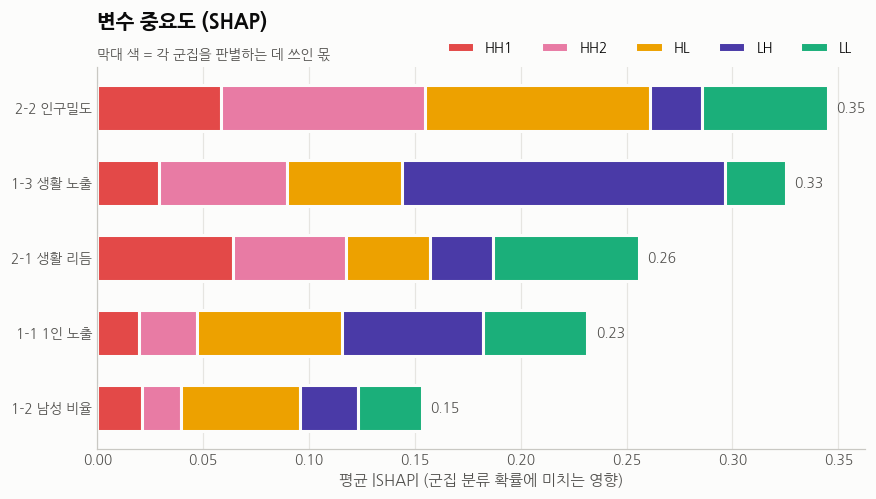

,HH1,HH2,HL,LH,LL
2-2 인구밀도,0.058,0.096,0.107,0.025,0.059
1-3 생활 노출,0.029,0.061,0.054,0.153,0.029
2-1 생활 리듬,0.064,0.053,0.040,0.030,0.069
1-1 1인 노출,0.019,0.028,0.068,0.066,0.049
1-2 남성 비율,0.021,0.018,0.056,0.027,0.030


In [25]:
# SHAP 값 계산 (TreeExplainer) - 결과 형태: [동 × 변수 × 군집]
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(Xs_df.values)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)    # shap 버전별 형태 통일
CLASSES = list(rf.classes_)
print('SHAP 배열 크기:', sv.shape, '| 군집 순서:', CLASSES)

# 전체 변수 중요도: 군집별 평균 |SHAP|
imp = pd.DataFrame({c: np.abs(sv[:, :, i]).mean(axis=0) for i, c in enumerate(CLASSES)}, index=Xs_df.columns)
imp = imp[[g for g in TG if g in imp.columns]]
order = imp.sum(axis=1).sort_values().index

fig, ax = plt.subplots(figsize=(9, 4.5))
left = np.zeros(len(order))
for gname in imp.columns:
    v = imp.loc[order, gname].values
    ax.barh(range(len(order)), v, left=left, color=CT[gname], label=gname, height=0.62, edgecolor=SURF, linewidth=2)
    left += v
ax.set_yticks(range(len(order)), order)
for i, tot in enumerate(left):
    ax.text(tot + 0.004, i, f'{tot:.2f}', va='center', fontsize=9, color=INK2)
ax.set_xlabel('평균 |SHAP| (군집 분류 확률에 미치는 영향)')
ax.set_title('변수 중요도 (SHAP)'); subtitle(ax, '막대 색 = 각 군집을 판별하는 데 쓰인 몫')
ax.legend(loc='lower right', bbox_to_anchor=(1, 1.0), ncol=5); clean(ax, grid='x'); plt.show()
imp.loc[order[::-1]].round(3)

**📌 해석**
- **2-2 인구밀도(0.35)와 1-3 생활 노출(0.33)이 군집을 가르는 핵심 변수**, 그다음 2-1 생활 리듬(0.26), 1-1 1인 노출(0.23)
- **1-2 남성 비율(0.15)은 가장 덜 쓰임** → 9-2에서 남성 비율을 빼도 위험 순위가 유지되던 결과와 일치
- 군집별로 쓰이는 변수가 다름
  - **HH1 (극고위험)**: 생활 리듬(0.064)·인구밀도(0.058) → 지역축이 극고위험을 결정
  - **HH2 (고위험)**: 인구밀도(0.096)·생활 노출(0.061)
  - **HL**: 인구밀도(0.107)·1인 노출(0.068)·남성 비율(0.056) → 인구축은 위험, 밀도는 높은 곳
  - **LH**: 생활 노출(0.153)이 압도적 → 5060이 거리에서 잘 보이는(활동적인) 곳
  - **LL**: 생활 리듬(0.069)·인구밀도(0.059) → 하루 종일 사람이 있고 붐비는 곳

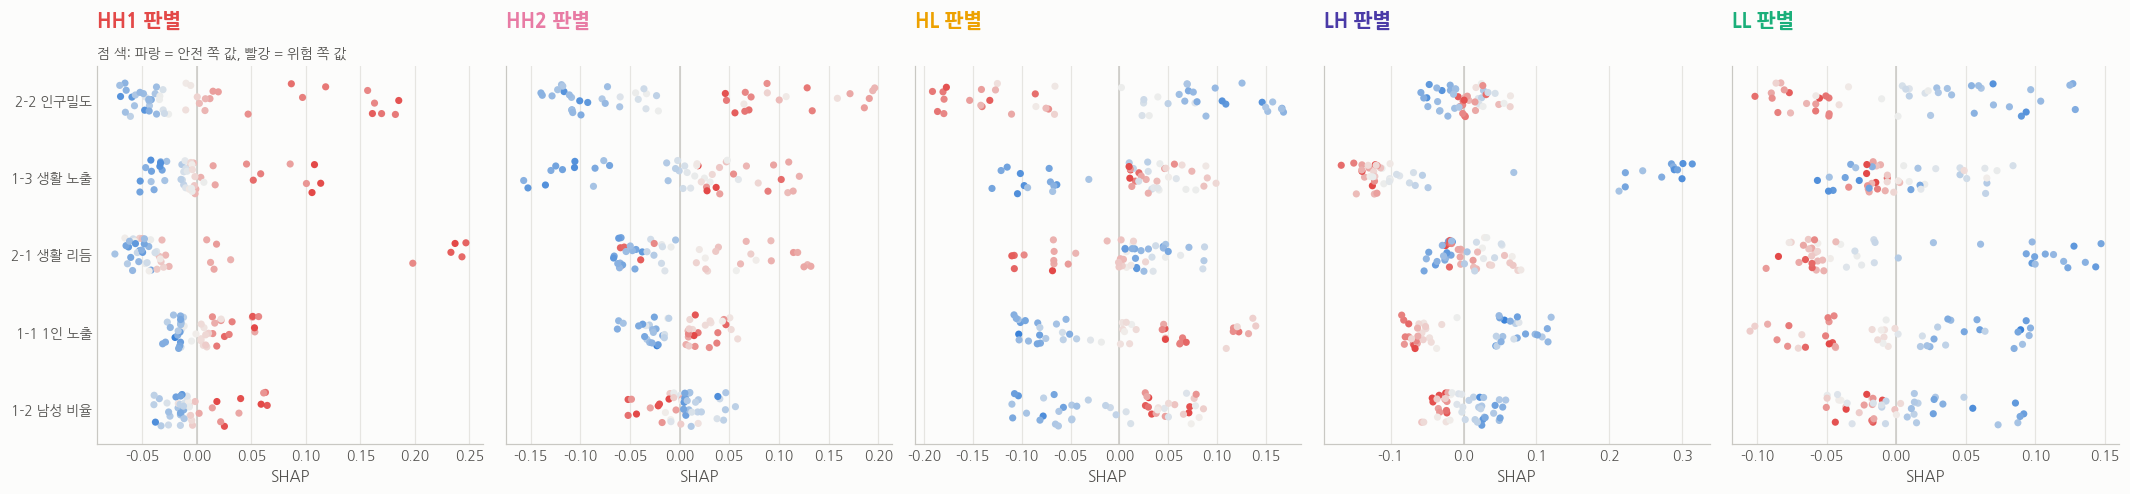

In [26]:
# 군집별 SHAP 분포 (beeswarm) - 점 = 동, 가로 = 그 군집일 확률에 미치는 영향, 색 = 변수 값(빨강 = 위험 쪽)
fig, axes = plt.subplots(1, len(imp.columns), figsize=(3.9 * len(imp.columns), 4.6), sharey=True)
rng_j = np.random.default_rng(0)
for ax, gname in zip(axes, imp.columns):
    ci = CLASSES.index(gname)
    for j, var in enumerate(order):
        vj = list(Xs_df.columns).index(var)
        x = sv[:, vj, ci]; c = Xs_df[var].values
        ax.scatter(x, j + rng_j.uniform(-0.22, 0.22, len(x)), c=c, cmap=DIV, vmin=-2, vmax=2, s=22,
                   edgecolor='none', zorder=3)
    ax.axvline(0, color='#c9c8c3', lw=1)
    ax.set_yticks(range(len(order)), order); ax.set_title(f'{gname} 판별', color=CT[gname])
    ax.set_xlabel('SHAP'); clean(ax, grid='x')
subtitle(axes[0], '점 색: 파랑 = 안전 쪽 값, 빨강 = 위험 쪽 값')
plt.tight_layout(); plt.show()

**📌 해석** (오른쪽으로 갈수록 그 군집으로 분류될 확률 ↑, 빨간 점 = 위험 쪽 값)
- **HH1 판별**: 2-1 생활 리듬의 **빨간 점이 가장 오른쪽(+0.2 이상)** 에 따로 모여 있고, 인구밀도의 빨간 점도 오른쪽 → 낮에만 사람이 있고 인구가 드문 곳
- **HH2 판별**: 인구밀도의 빨간 점(밀도 낮음)이 오른쪽, 생활 노출의 파란 점(5060이 잘 보임)은 왼쪽 → 밀도가 낮고 5060이 덜 보일수록 HH2
- **HL 판별**: 인구밀도는 **파란 점(밀도 높음)이 오른쪽**, 1인 노출은 빨간 점이 오른쪽 → '1인 세대는 많지만 붐비는 곳'
- **LH 판별**: 1-3 생활 노출의 **파란 점(5060이 잘 보임)이 +0.2\~0.3으로 크게 오른쪽** → 5060이 활동적인 곳
- **LL 판별**: 생활 리듬·인구밀도·1인 노출 모두 파란 점이 오른쪽 → 모든 변수가 안전 쪽

### 10-1. 동별 설명 - 왜 이 군집인가

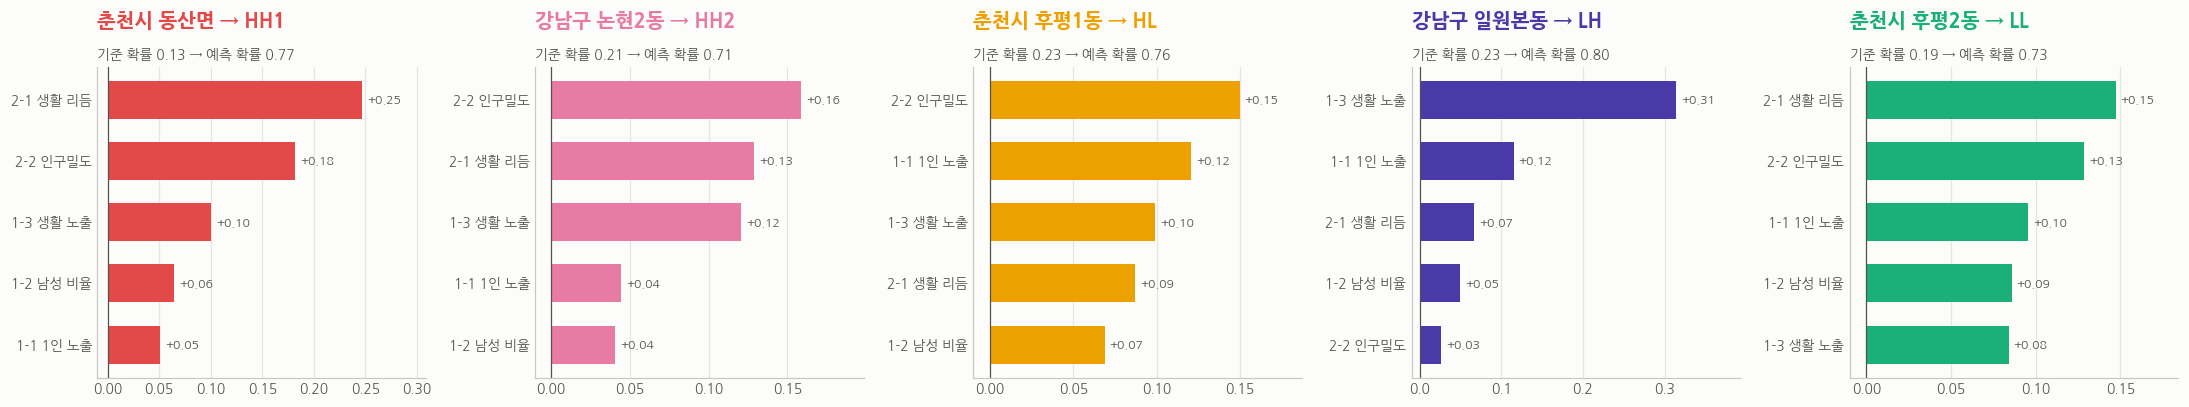

In [27]:
def explain_dong(emd_cd, top=5):
    """해당 동이 속한 군집 확률을 각 변수가 얼마나 올리고/내렸는지"""
    i = feat.index.get_loc(emd_cd); gname = feat.GROUP_T.iloc[i]; ci = CLASSES.index(gname)
    s = pd.Series(sv[i, :, ci], index=Xs_df.columns).sort_values(key=np.abs, ascending=False)
    return gname, s.head(top), explainer.expected_value[ci] if np.ndim(explainer.expected_value) else explainer.expected_value

# 대표 동: 군집별로 대리 모델이 그 군집일 확률을 가장 높게 준 동 (가장 전형적인 동)
proba = pd.DataFrame(rf.predict_proba(Xs_df.values), index=feat.index, columns=CLASSES)
feat['P_OWN'] = [proba.at[i, gname] for i, gname in zip(feat.index, feat.GROUP_T)]
rep = feat.sort_values('P_OWN', ascending=False).groupby('GROUP_T').head(1)
rep = rep.set_index('GROUP_T').reindex(TG).dropna(subset=['EMD_NM'])

fig, axes = plt.subplots(1, len(rep), figsize=(4.0 * len(rep), 3.8))
for ax, (gname, r) in zip(np.atleast_1d(axes), rep.iterrows()):
    emd_cd = feat.index[(feat.EMD_NM == r.EMD_NM) & (feat.SGG_NM == r.SGG_NM)][0]
    _, s, base = explain_dong(emd_cd)
    s = s[::-1]
    colors = [CT[gname] if v > 0 else '#c9c8c3' for v in s.values]
    ax.barh(range(len(s)), s.values, color=colors, height=0.62)
    ax.set_yticks(range(len(s)), s.index); ax.axvline(0, color=INK2, lw=0.8)
    lo, hi = min(s.min(), 0), max(s.max(), 0); pad = (hi - lo) * 0.25
    ax.set_xlim(lo - (pad if lo < 0 else 0.01), hi + pad)                 # 값 라벨이 축 이름과 겹치지 않게 여백
    for y_, v in enumerate(s.values):
        ax.text(v + (pad * 0.08 if v >= 0 else -pad * 0.08), y_, f'{v:+.2f}', va='center',
                ha='left' if v >= 0 else 'right', fontsize=8, color=INK2)
    p = rf.predict_proba(Xs_df.loc[[emd_cd]].values)[0][CLASSES.index(gname)]
    ax.set_title(f'{r.SGG_NM} {r.EMD_NM} → {gname}', color=CT[gname])
    subtitle(ax, f'기준 확률 {base:.2f} → 예측 확률 {p:.2f}')
    clean(ax, grid='x')
plt.tight_layout(); plt.show()

In [28]:
# 동별 군집 판별 근거 요약표 (AI 에이전트 '위험 원인 분석' 입력용)
#   각 동이 속한 군집 확률을 가장 크게 올린 변수 2개 + 그 변수 값이 위험 쪽인지 안전 쪽인지
#   (예: LL 동의 '인구밀도'는 밀도가 높아서(안전 쪽) LL로 분류됐다는 뜻 → 위험 원인이 아님)
def reason(emd_cd, var, v):
    side = '위험' if Xs_df.at[emd_cd, var] > 0 else '안전'
    return f'{var} ({side} 쪽, {v:+.2f})'

rows = []
for emd_cd in feat.index:
    gname, s, _ = explain_dong(emd_cd, top=len(VARS))
    pos = s[s > 0].sort_values(ascending=False)
    rows.append({'시군구': feat.at[emd_cd, 'SGG_NM'], '동': feat.at[emd_cd, 'EMD_NM'], '군집': gname,
                 '위험도': feat.at[emd_cd, 'RISK_LEVEL'],
                 '판별 근거 1': reason(emd_cd, pos.index[0], pos.iloc[0]) if len(pos) > 0 else '-',
                 '판별 근거 2': reason(emd_cd, pos.index[1], pos.iloc[1]) if len(pos) > 1 else '-'})
cause = pd.DataFrame(rows)
cause['군집'] = pd.Categorical(cause.군집, TG)
cause.sort_values(['군집', '위험도'], ascending=[True, False]).reset_index(drop=True)

,시군구,동,군집,위험도,판별 근거 1,판별 근거 2
0,강남구,삼성1동,HH1,5,"2-1 생활 리듬 (위험 쪽, +0.24)","2-2 인구밀도 (위험 쪽, +0.16)"
1,춘천시,동산면,HH1,5,"2-1 생활 리듬 (위험 쪽, +0.25)","2-2 인구밀도 (위험 쪽, +0.18)"
2,춘천시,남면,HH1,5,"2-2 인구밀도 (위험 쪽, +0.17)","1-3 생활 노출 (위험 쪽, +0.11)"
3,춘천시,서면,HH1,5,"2-1 생활 리듬 (위험 쪽, +0.24)","2-2 인구밀도 (위험 쪽, +0.16)"
4,춘천시,북산면,HH1,5,"2-1 생활 리듬 (위험 쪽, +0.23)","2-2 인구밀도 (위험 쪽, +0.19)"
5,춘천시,남산면,HH1,5,"2-1 생활 리듬 (위험 쪽, +0.20)","2-2 인구밀도 (위험 쪽, +0.16)"
6,강남구,논현2동,HH2,5,"2-2 인구밀도 (위험 쪽, +0.16)","2-1 생활 리듬 (위험 쪽, +0.13)"
7,강남구,역삼1동,HH2,5,"2-1 생활 리듬 (위험 쪽, +0.12)","2-2 인구밀도 (위험 쪽, +0.11)"
8,춘천시,신동면,HH2,5,"2-2 인구밀도 (위험 쪽, +0.19)","2-1 생활 리듬 (위험 쪽, +0.13)"
9,춘천시,사북면,HH2,5,"2-2 인구밀도 (위험 쪽, +0.13)","2-1 생활 리듬 (위험 쪽, +0.09)"


**📌 해석** (막대 = 그 동이 해당 군집으로 분류될 확률을 각 변수가 올린 정도, 대표 동 = 대리 모델이 가장 확신한 동)
- **춘천 동산면 → HH1 (확률 0.77)**: 생활 리듬(+0.25)·인구밀도(+0.18) → 하루 중 비어 있는 시간이 길고 인구가 드문 곳
- **강남 논현2동 → HH2 (0.71)**: 인구밀도(+0.16)·생활 리듬(+0.13)·생활 노출(+0.12)
- **춘천 후평1동 → HL (0.76)**: 인구밀도(+0.15, 안전 쪽)와 1인 노출(+0.12, 위험 쪽) → 1인 세대는 많지만 붐비는 곳
- **강남 일원본동 → LH (0.80)**: 생활 노출(+0.31, 안전 쪽) → 5060이 거리에서 활발히 보임
- **춘천 후평2동 → LL (0.73)**: 생활 리듬(+0.15)·인구밀도(+0.13) 모두 안전 쪽 → 고밀도 아파트 단지

**판별 근거 표 활용** (위험도 = 8장 최종 모델 기준)
- **HH1 6개 동**(춘천 동산면·남면·서면·북산면·남산면, 강남 삼성1동)은 남면(인구밀도 + 생활 노출)을 빼면 모두 '생활 리듬 + 인구밀도'가 위험 쪽 → **시간적·공간적 고립**이 극고위험의 원인
- **HH2 10개 동**: 춘천 신동면·사북면·신북읍은 인구밀도 + 생활 리듬, 강남 신사동·압구정동·청담동·수서동은 인구밀도 + 생활 노출, 역삼1동·대치2동은 생활 리듬 중심
- HL 동은 '1인 노출(위험 쪽)'이 위험 원인, '인구밀도(안전 쪽)'는 위험을 낮추는 요인
- LH·LL 동의 근거는 대부분 '안전 쪽' 값 → **위험 원인이 아니라 안전한 이유**로 읽어야 함
- 👉 AI 에이전트는 HH1·HH2·HL 동에 대해 '위험 쪽' 근거만 골라 **"이 동은 ○○ 때문에 고위험"** 형태의 설명을 생성하는 데 활용

## 결과 요약
1. 지역축을 **생활 리듬 다양성(TIME_ENTROPY) + 인구밀도(POP_DENSITY)** 로 교체 → 5개 변수 모두 같은 위험 방향(상관 0 이상)
2. 64개 조합 튜닝 후 **최종 모델 = 2D z-score + K-means, K=5** (부트스트랩 안정성 0.81, 기본 모델 0.76)
3. 군집: **HH1 6 / HH2 10 / HL 11 / LH 11 / LL 9** (논문과 같은 사분면 이름)
   - HH1 극고위험: 춘천 남면·서면·동산면·남산면·북산면, 강남 삼성1동
4. **위험도 5단계 (10개 동)**: 춘천 서면·남면·동산면·북산면·남산면·신동면·사북면 + 강남 삼성1동·역삼1동·논현2동 (단계 점수 합 기준, 에이전트 파일과 동일)
5. 위험도 순위는 점수 방식·가중치·변수 구성을 바꿔도 순위상관 0.92\~0.99, 상위 10개 동 8\~10개 일치
6. 군집을 가르는 핵심 변수(SHAP)는 **인구밀도·생활 노출**, 극고위험(HH1)은 **생활 리듬 + 인구밀도**

## 한계
- 강남 5단계의 삼성1동·역삼1동은 업무지구 특성(낮 시간 집중, 강남 안에서 낮은 밀도)이 반영된 결과
- 춘천 외곽 면은 5060 인구가 470\~1,598명으로 적어 비율 변수가 흔들릴 수 있음
- 군집 경계는 인구밀도 포함 여부에 민감(ARI 0.43), 판단 규칙의 재현 정확도는 0.63 → 군집 이름보다 **위험도 단계가 더 견고한 결과**
- LH 군집의 지역축은 중앙에 가까워(단계 점수 3.09) '지역 위험'보다는 '지역 평균 수준'으로 해석해야 함
- 정답(실제 고독사) 데이터가 없어 외부 검증은 하지 못함 → 무료 공공데이터(동별 기초생활수급자 등)와 순위 비교 필요